In [1]:
print('In the name of Allah')

In the name of Allah


# Linear Regression from Scratch
In this notebook, we will explore the fundamentals of Linear Regression. We'll start by visualizing data, then manually tune parameters, and finally implement Gradient Descent to find the optimal fit.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set default styles for our plots
sns.set_theme()

## 1. Data Preparation
We'll define a simple dataset representing years of experience and the corresponding salary.

In [3]:
X = np.array([1 , 3, 4, 6, 7]) # Input feature: years of experience
y = np.array([15,35,45,65,75]) # Target value: salary (in thousands)

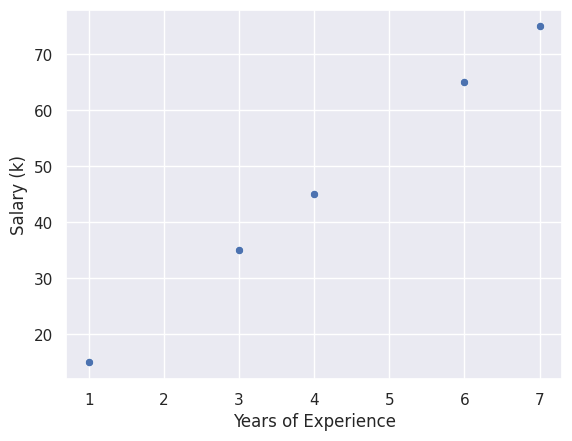

In [26]:
# Visualize the relationship between experience and salary
sns.scatterplot(x=X, y=y)
plt.xlabel("Years of Experience")
plt.ylabel("Salary (k)")
plt.show()

## 2. Prediction Function
The linear model is defined as $f(x) = wx + b$. Here we create a function to generate predictions for our dataset.

In [27]:
def make_prediction(X, y, w, b):
  """Calculates the model output: f(x) = wx + b"""

  m = X.shape[0] # Number of training examples
  pred_list = np.zeros((m,)) # Initialize an array to store results

  for i in range(m):
    # Apply the linear regression formula
    pred_list[i] = w * X[i] + b

  return pred_list

Predictions (0,0): [0. 0. 0. 0. 0.]


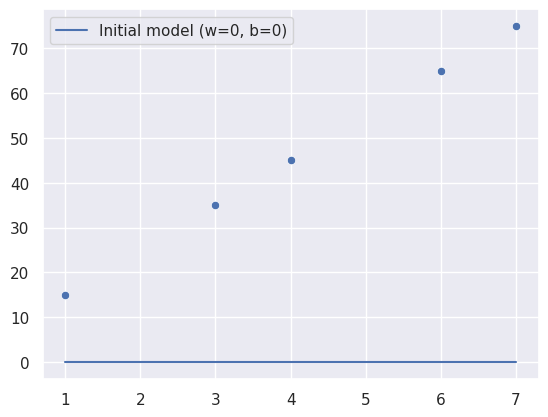

In [28]:
# Initial test with parameters w=0 and b=0
predictions = make_prediction(X, y, 0, 0)
print(f"Predictions (0,0): {predictions}")

# Plot actual data vs initial predictions
sns.scatterplot(x=X, y=y)
plt.plot(X, predictions, label='Initial model (w=0, b=0)')
plt.legend()
plt.show()

[1. 3. 4. 6. 7.]


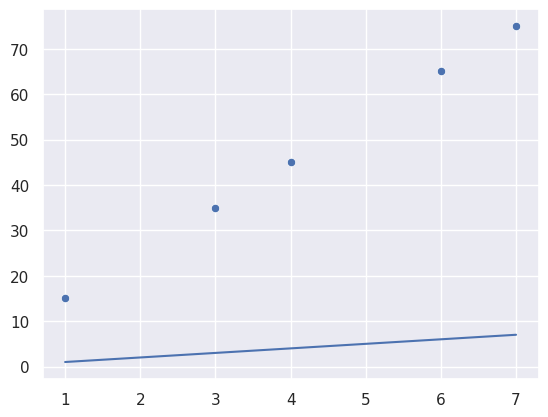

In [29]:
predictions = make_prediction(X,y,w=1,b=0)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

[ 8. 18. 23. 33. 38.]


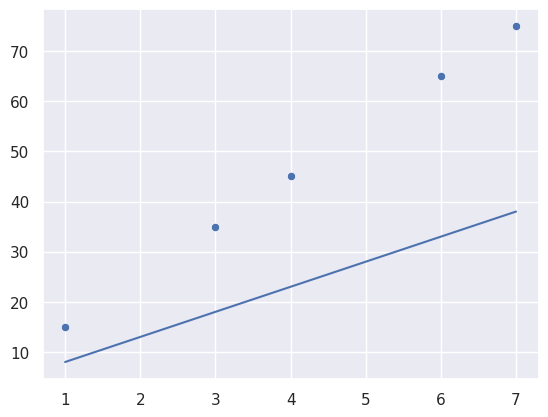

In [30]:
predictions = make_prediction(X,y,w=5,b=3)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

[15. 35. 45. 65. 75.]


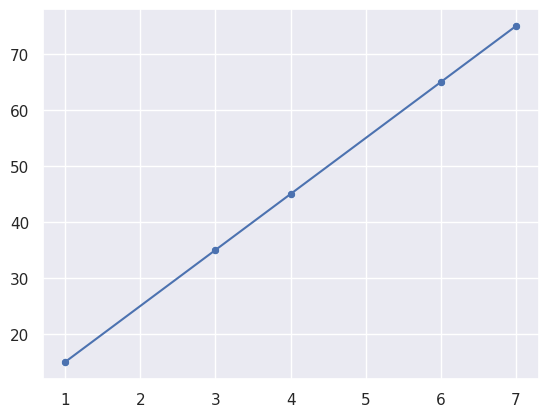

In [31]:
predictions = make_prediction(X,y,w=10,b=5)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

## 3. Cost Function
To evaluate how well our model fits, we calculate the 'Cost' (Mean Squared Error). A lower cost means a better fit.

### Cost Function Formula
The Mean Squared Error (MSE) cost function is defined as:

$$J(w,b) = \frac{1}{2m} \sum_{i=0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})^2$$

Where:
* $m$ is the number of training examples.
* $f_{w,b}(x^{(i)}) = wx^{(i)} + b$ is the model's prediction.
* $y^{(i)}$ is the target value.

In [32]:
def compute_cost( X, y, w, b ) :

  """Calculates the Mean Squared Error (MSE) to measure model accuracy"""

  m = X.shape[0]
  cost = 0.0

  for i in range( m ):

    prediction = w * X[i] + b
    error = prediction - y[i] # Difference between prediction and actual value

    error_squared = error ** 2

    cost = cost + error_squared

  # We divide by 2m for mathematical convenience in gradient calculations

  cost = cost / ( 2 * m )

  return cost


[0. 0. 0. 0. 0.]


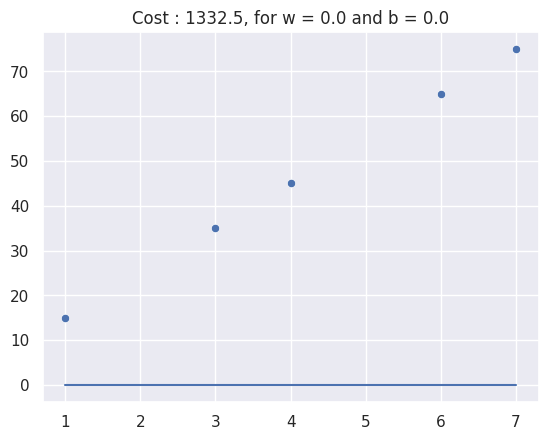

In [33]:
w = 0.0
b = 0.0

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
print(predictions)

sns.scatterplot(x = X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

[1. 3. 4. 6. 7.]


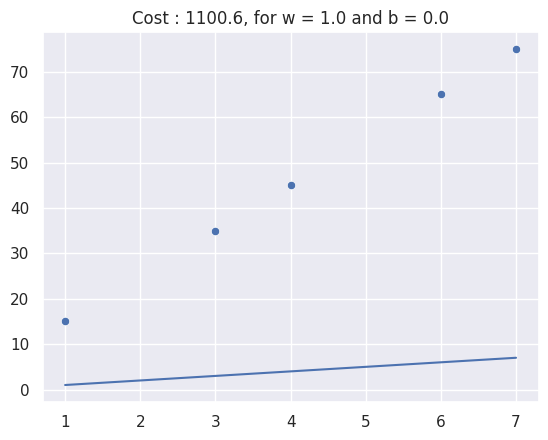

In [34]:
w = 1.0
b = 0.0

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

[ 3.  7.  9. 13. 15.]


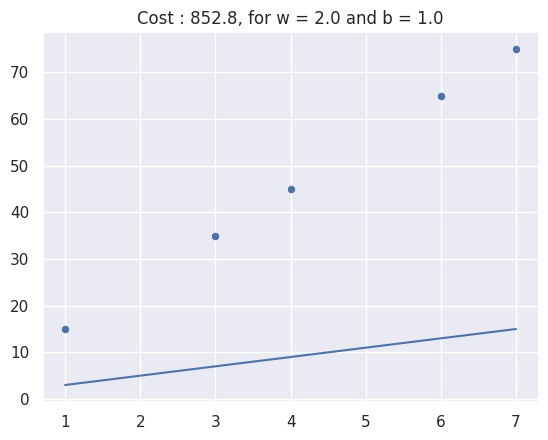

In [35]:
w = 2.0
b = 1.0

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

[15. 35. 45. 65. 75.]


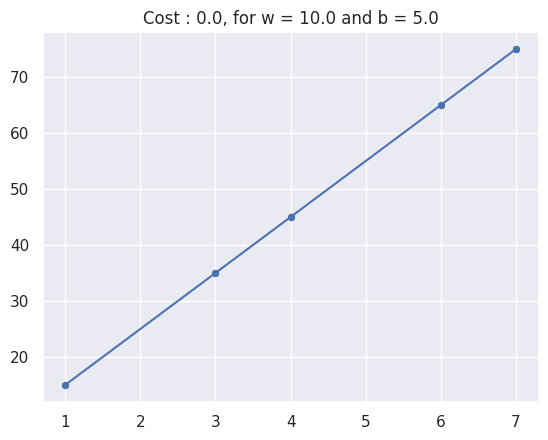

In [36]:
w = 10.0
b = 5.0

# Calculate predictions and evaluate cost manually

predictions = make_prediction(X, y, w = w, b = b)
print(predictions)

sns.scatterplot(x= X , y = y)
plt.plot(X ,predictions)

# The title shows the cost, helping us see how 'wrong' our line is

plt.title(f'Cost : {compute_cost(X, y, w = w, b = b)}, for w = {w} and b = {b}')
plt.show()

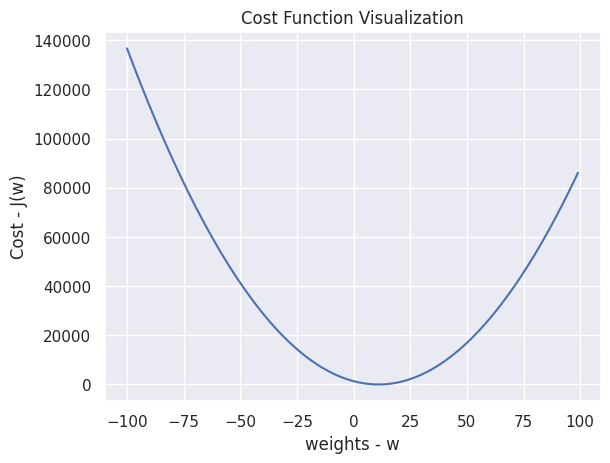

In [37]:
w_range = []
cost_history = []

# Loop through different weight values to see how they affect the cost
for i in range(-100, 100):
    cost_i = compute_cost(X, y, w=i, b=0)
    w_range.append(i)
    cost_history.append(cost_i)

# Plotting the Cost Function: The goal of ML is to find the bottom of this 'U'

plt.plot(w_range, cost_history)
plt.xlabel("weights - w")
plt.ylabel("Cost - J(w)")
plt.title("Cost Function Visualization")

plt.show()

## 5. Gradient Descent
Instead of guessing, we use the gradient (slope) to update $w$ and $b$ automatically until the cost is minimized.

### Gradient Descent Update Rules

The weight ($w$) and bias ($b$) are updated simultaneously using the following formulas:

$$w := w - \alpha \frac{\partial J(w,b)}{\partial w}$$

$$b := b - \alpha \frac{\partial J(w,b)}{\partial b}$$

*Where:*
* **$\alpha$**: The learning rate.
* **$\frac{\partial J}{\partial w}$**: The gradient with respect to the weight.
* **$\frac{\partial J}{\partial b}$**: The gradient with respect to the bias.

### Gradient Calculation Formulas
To update the parameters, we calculate the partial derivatives of the cost function $J(w,b)$:

$$\frac{\partial J(w,b)}{\partial w} = \frac{1}{m} \sum_{i=0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)}$$

$$\frac{\partial J(w,b)}{\partial b} = \frac{1}{m} \sum_{i=0}^{m-1} (f_{w,b}(x^{(i)}) - y^{(i)})$$


In [38]:
def calculate_gradient(X, y, w, b):

  """Computes the gradient (direction to move) for w and b"""

  m = X.shape[0]

  dj_dw = 0.0 # Change needed for weight
  dj_db = 0.0 # Change needed for bias

  for i in range(m):

    prediction = w * X[i] + b
    error = prediction - y[i]

    # Multiply error by X[i] for the weight gradient

    dj_dw = dj_dw + (error * X[i])

    # The bias gradient is just the sum of errors

    dj_db = dj_db + error

  return dj_dw / m, dj_db / m

In [39]:
calculate_gradient( X, y, w = 3, b = 0 )

(np.float64(-176.4), np.float64(-34.4))

In [45]:
def gradient_descent( X, y, w_input, b_input, max_iter, alpha = 0.01 ) : # Best value of alpha

  """Automates the tuning of w and b to minimize cost"""

  w = w_input
  b = b_input

  cost_memo = []
  iteration = []

  for i in range(max_iter) :
    # 1. Calculate the gradients (the slope)

    dj_dw, dj_db = calculate_gradient(X, y, w, b)

    # 2. Update parameters by taking a small step (alpha) against the gradient

    w = w - alpha * dj_dw
    b = b - alpha * dj_db

    # 3. Track progress by saving the cost

    cost = compute_cost( X, y, w, b )
    cost_memo.append( cost )
    iteration.append(i)

    # Log the status every 100 steps
    if i % 100 == 0 :
      print( f'Iteration : {i}, w : {w:0.4f}, b : {b:0.4f}, dj_dw : {dj_dw:0.4f}, dj_db : {dj_db:0.4f}, cost : {cost:0.4f}' )

  return w, b, cost_memo, iteration


### Run Gradient Descent
We initialize $w$ and $b$ at 0 and let the algorithm find the best values.

In [46]:
# Run gradient descent and store the results in w_final and b_final

w_final, b_final, cost_memo, iter_list = gradient_descent( X, y, w_input = 0, b_input = 0, max_iter = 10000, alpha = 0.01 )

Iteration : 0, w : 2.4300, b : 0.4700, dj_dw : -243.0000, dj_db : -47.0000, cost : 790.3717
Iteration : 100, w : 10.4659, b : 2.5593, dj_dw : 0.0926, dj_db : -0.4848, cost : 0.6120
Iteration : 200, w : 10.3821, b : 2.9986, dj_dw : 0.0759, dj_db : -0.3976, cost : 0.4115
Iteration : 300, w : 10.3133, b : 3.3588, dj_dw : 0.0622, dj_db : -0.3260, cost : 0.2767
Iteration : 400, w : 10.2569, b : 3.6542, dj_dw : 0.0510, dj_db : -0.2673, cost : 0.1861
Iteration : 500, w : 10.2107, b : 3.8965, dj_dw : 0.0418, dj_db : -0.2192, cost : 0.1251
Iteration : 600, w : 10.1727, b : 4.0951, dj_dw : 0.0343, dj_db : -0.1798, cost : 0.0841
Iteration : 700, w : 10.1416, b : 4.2580, dj_dw : 0.0281, dj_db : -0.1474, cost : 0.0566
Iteration : 800, w : 10.1162, b : 4.3915, dj_dw : 0.0231, dj_db : -0.1209, cost : 0.0380
Iteration : 900, w : 10.0952, b : 4.5010, dj_dw : 0.0189, dj_db : -0.0991, cost : 0.0256
Iteration : 1000, w : 10.0781, b : 4.5909, dj_dw : 0.0155, dj_db : -0.0813, cost : 0.0172
Iteration : 1100,

Have a look at the dj_dw and dj_db section. The values are decreasing and tending to zero over the iterations. That means , once the algorithm converges to it's minimum point of the function , it kinda stop updating the parameters ( w and b )

## 6. Final Results & Prediction
Now we can use our optimized parameters to predict the salary for someone with 2 years of experience.

Optimized w: 10.0000, b: 5.0000


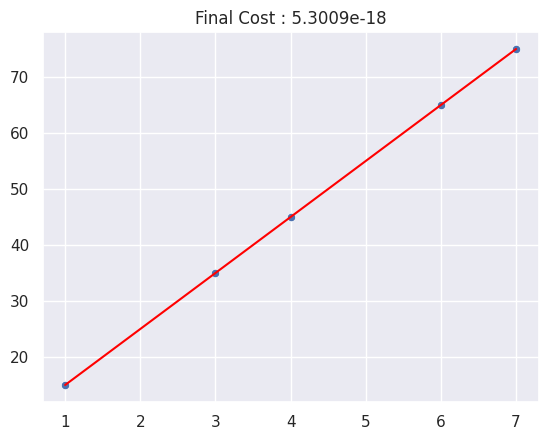

In [47]:
print(f"Optimized w: {w_final:0.4f}, b: {b_final:0.4f}")

# Get final predictions based on optimized parameters

final_preds = make_prediction(X, y, w = w_final, b = b_final)
# print(final_preds)

sns.scatterplot(x= X , y = y)

plt.plot(X ,final_preds, color = 'red', label = 'Best Fit Line')

plt.title(f'Final Cost : {compute_cost(X, y, w = w_final, b = b_final):0.4e}')
plt.show()

In [48]:
# Example: Predicting salary for someone with 2 years of experience

x_new = 2

# Using the formula f(x) = wx + b with our final calculated parameters

prediction = w_final * x_new + b_final

print(f"Predicted salary for {x_new} years of experience: {prediction:0.2f}k")

Predicted salary for 2 years of experience: 25.00k


Text(0, 0.5, 'Cost')

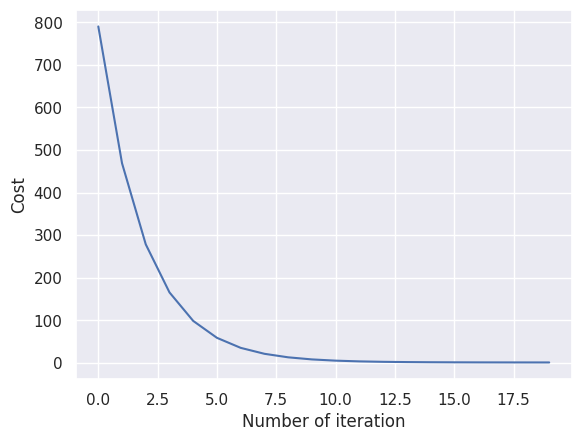

In [51]:
# Plot the cost over the first 20 iterations to see it dropping

plt.plot(iter_list[:20], cost_memo[:20])
plt.xlabel('Number of iteration')
plt.ylabel('Cost')
